# 线性回归

### 问题

给一堆 (x, y) 点,想找一条直线 y = wx + b,让预测值尽量贴近真实值。贴不贴近用均方误差来量:

$$L(w,b)=\frac{1}{n}\sum_{i=1}^{n}(wx_i+b-y_i)^2$$

对 w 和 b 分别求偏导,得到梯度:

$$\frac{\partial L}{\partial w}=\frac{2}{n}\sum_{i=1}^{n}(wx_i+b-y_i)x_i,\qquad \frac{\partial L}{\partial b}=\frac{2}{n}\sum_{i=1}^{n}(wx_i+b-y_i)$$

梯度下降就是每次往反方向走一步:$w \leftarrow w-\eta\frac{\partial L}{\partial w}$。

这一节先用最直白的循环把上面两行写成代码,再封装成类,最后和正规方程、sklearn 对一下结果。

## 1. 造一份数据

真实关系是 y = 2.5x + 5,再叠一点噪声。后面就看能不能把 2.5 和 5 学回来。

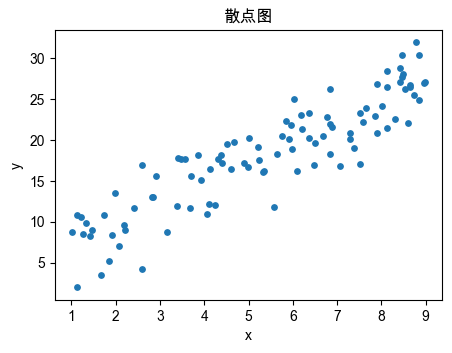

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt

# 本机 numpy 2.0 会对 matmul 误报浮点警告,结果是对的
warnings.filterwarnings("ignore", message=".*in matmul")

# 中文和负号
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

rng = np.random.default_rng(0)
x = rng.uniform(1, 9, 100)
y = 2.5 * x + 5 + rng.normal(0, 3, 100)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(x, y, s=15)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("散点图")
plt.show()

x 在 1 到 9 之间,y 跟着往上走,整体落在 2 到 32 之间,点绕着一条直线散开。噪声标准差是 3,理论上的 loss 下限就是 9,所以再好的模型也降不到 0。

## 2. 先手写一遍梯度下降

两个参数从 0 开始,每步算一次梯度再更新。为了看清 loss 怎么变,把每一步的 MSE 都存下来。

In [2]:
w, b = 0.0, 0.0
lr = 0.01
loss_history = []

for _ in range(1000):
    err = (w * x + b) - y
    w -= lr * 2 * np.mean(err * x)
    b -= lr * 2 * np.mean(err)
    loss_history.append(np.mean(err ** 2))

print(f"w={w:.4f} b={b:.4f} loss={loss_history[-1]:.4f}")

w=2.4770 b=4.8588 loss=8.4652


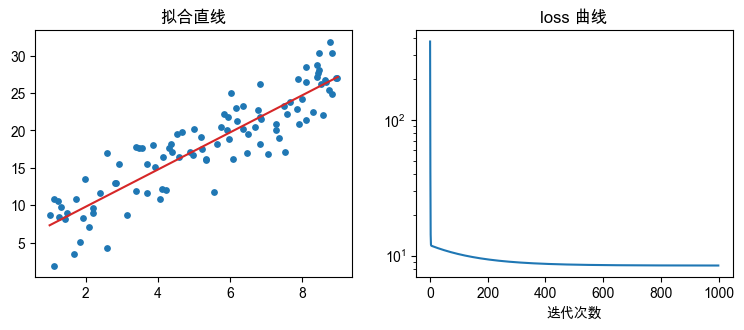

In [3]:
xs = np.linspace(1, 9, 100)

fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))

axs[0].scatter(x, y, s=15)
axs[0].plot(xs, w * xs + b, color="tab:red")
axs[0].set_title("拟合直线")

axs[1].set_yscale("log")
axs[1].plot(loss_history)
axs[1].set_xlabel("迭代次数")
axs[1].set_title("loss 曲线")
plt.show()

学出来的 w 是 2.477,b 是 4.859,已经贴着真值 2.5 和 5 了,但没完全到。loss 从 376 降到 8.465,而这个数据的最优值是 8.4605,差的这一点就是还没收敛干净。

## 3. 封装成类

循环里那三行梯度就是全部逻辑,包一层方便复用:接口照 sklearn 的样子做,`fit` 训练,`predict` 预测,`score` 返回 R²。代码在 [linear_regression.py](linear_regression.py)。

In [4]:
from linear_regression import LinearRegression, mse

model = LinearRegression(lr=0.01, n_iters=1000).fit(x, y)

print(round(model.coef_[0], 4), round(model.intercept_, 4))
print("和手写循环一致:", np.allclose([model.coef_[0], model.intercept_], [w, b]))
print("R²:", round(model.score(x, y), 4))
print("MSE:", round(mse(y, model.predict(x)), 4))

2.477 4.8588
和手写循环一致: True
R²: 0.8066
MSE: 8.4652


同一份数据同样的步数,结果和上面手写的完全一样。`coef_` 和 `intercept_` 后面带下划线是 sklearn 的习惯,表示这两个值要等 `fit` 之后才有。

## 4. 学习率

lr 决定每步走多远。太小要迭代很多次,太大就会在最低点两边来回蹦,越蹦越高。

In [5]:
for lr in [0.001, 0.01, 0.02, 0.05]:
    m = LinearRegression(lr=lr, n_iters=200).fit(x, y)
    print(f"lr={lr:<6} loss={m.loss_history_[-1]:>10.3g} w={m.coef_[0]:>8.3g}")

lr=0.001  loss=      11.5 w=    3.11
lr=0.01   loss=      9.39 w=    2.81
lr=0.02   loss=      8.71 w=    2.64
lr=0.05   loss= 5.26e+166 w=-3.79e+82


lr=0.05 的 loss 已经到 5e166,再跑几步就变成 inf,画出来会把别的曲线压没,所以下面只画前面三条,纵轴取对数。

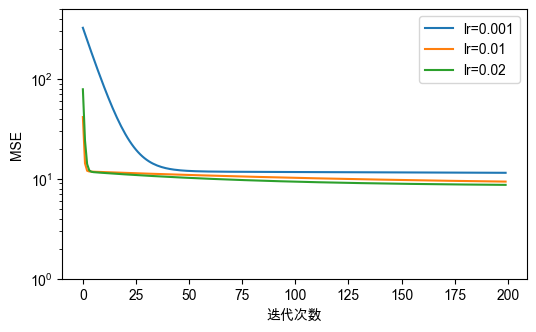

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))

for lr in [0.001, 0.01, 0.02]:
    m = LinearRegression(lr=lr, n_iters=200).fit(x, y)
    ax.plot(m.loss_history_, label=f"lr={lr}")

ax.set_yscale("log")
ax.set_xlabel("迭代次数")
ax.set_ylabel("MSE")
ax.set_ylim(1, 500)
ax.legend()
plt.show()

同样 200 步,lr=0.001 还停在 11.5,lr=0.02 已经到 8.71。步长要跟损失面的陡峭程度匹配,太大了会一步跨过最低点,下一步被弹得更远。

这里 x 在 1 到 9 之间,梯度里带着 x 和 x²,和参数本身差着量级,所以 lr 的上限被压得很低。

## 5. 先标准化再训练

把 x 减均值除标准差,变成均值 0、方差 1 的数,梯度就不会被 x 的量级拖累。学完再按线性关系还原回去。

In [7]:
mu, sigma = x.mean(), x.std()
xz = (x - mu) / sigma

model_z = LinearRegression(lr=0.1, n_iters=100).fit(xz, y)
print("标准化后 100 步 loss:", round(model_z.loss_history_[-1], 4))

w_z, b_z = model_z.coef_[0], model_z.intercept_
print("还原后 w, b:", round(w_z / sigma, 4), round(b_z - w_z * mu / sigma, 4))

short = LinearRegression(lr=0.01, n_iters=100).fit(x, y)
print("不标准化 100 步 loss:", round(short.loss_history_[-1], 4))

标准化后 100 步 loss: 8.4605
还原后 w, b: 2.451 5.0266
不标准化 100 步 loss: 10.2548


同样 100 步,标准化之后 lr 用到 0.1 也没事,loss 直接到最优 8.4605;不标准化的还停在 10.25。

还原就是把 $y=w_z\frac{x-\mu}{\sigma}+b_z$ 展开成 $y=wx+b$,所以 $w=w_z/\sigma$,$b=b_z-w_z\mu/\sigma$。这一步做错了不会报错,只会得到一组看着对、其实错位的系数。

## 6. 正规方程

最小二乘是有闭式解的。把 b 并进参数里(给 X 补一列 1),令梯度为零,得到:

$$\theta=(X^TX)^{-1}X^Ty$$

不用调 lr,也不管迭代多少次,一次算完。

In [8]:
normal = LinearRegression(method="normal").fit(x, y)

print(round(normal.coef_[0], 4), round(normal.intercept_, 4))
print("R²:", round(normal.score(x, y), 4))
print("MSE:", round(mse(y, normal.predict(x)), 4))
print("和梯度下降差多少:", np.abs(normal.coef_ - model.coef_).round(4))

2.451 5.0266
R²: 0.8068
MSE: 8.4605
和梯度下降差多少: [0.026]


正规方程给的是精确最优解。上面梯度下降跑了 1000 步还差 0.026,跑到 3000 步才基本对上。特征少的时候闭式解更省事。

但 $X^TX$ 要求逆,维度 d 大时是 O(d³),而且特征之间线性相关时这个矩阵接近奇异,`solve` 会直接报错:

In [9]:
x_dup = np.c_[x, x * 2]   # 第二列是第一列的倍数

try:
    LinearRegression(method="normal").fit(x_dup, y)
except np.linalg.LinAlgError:
    print("X^T X 奇异,解不出来")

X^T X 奇异,解不出来


## 7. 多特征:糖尿病数据

换成 sklearn 自带的糖尿病数据,10 个特征、442 条样本,预测的是一年后病情进展的指标。

In [10]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

diabetes = load_diabetes()
X, y_d = diabetes.data, diabetes.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y_d, test_size=0.2, random_state=0)

print(X_train.shape, X_test.shape)

(353, 10) (89, 10)


In [11]:
mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0)
X_train_s = (X_train - mu) / sigma
X_test_s = (X_test - mu) / sigma

model = LinearRegression(lr=0.05, n_iters=20000).fit(X_train_s, y_train)
print("train R²:", round(model.score(X_train_s, y_train), 4))
print("test  R²:", round(model.score(X_test_s, y_test), 4))

train R²: 0.5539
test  R²: 0.3322


和 sklearn 的 `LinearRegression` 对一下,系数和 R² 应该几乎一样:

In [12]:
from sklearn.linear_model import LinearRegression as SklearnLR

sk = SklearnLR().fit(X_train_s, y_train)
print("sklearn test R²:", round(sk.score(X_test_s, y_test), 4))
print("系数最大差:", np.abs(model.coef_ - sk.coef_).max())

sklearn test R²: 0.3322
系数最大差: 2.0449868287641948e-07


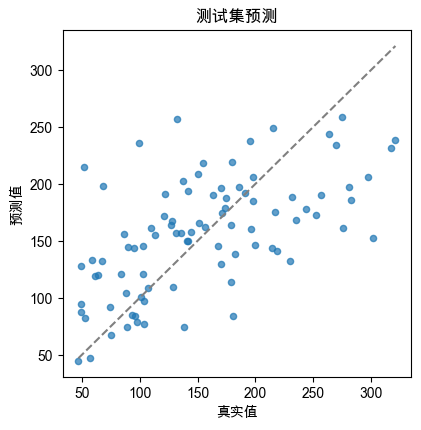

In [13]:
y_pred = model.predict(X_test_s)

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(y_test, y_pred, s=20, alpha=0.7)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
        color="gray", linestyle="--")
ax.set_xlabel("真实值")
ax.set_ylabel("预测值")
ax.set_title("测试集预测")
plt.show()

R² 只有 0.33,这个数据集噪声本来就大,线性模型差不多就这个水平,想再往上得换更复杂的模型。

系数要到小数点后 7 位才和 sklearn 对上。原因是 s1 和 s2 的相关系数有 0.9,s3 和 s4 也有 0.74,特征之间互相拉扯,损失面被压得很扁,梯度下降得走两万步。单特征那组数据 100 步就够了。

## 8. 小结

- 线性回归的损失是凸的,梯度下降一定往全局最优走,但快慢严重依赖 lr 和特征尺度;
- 特征量纲差得多时先标准化,lr 能放大一个数量级,迭代次数少一个数量级;
- 正规方程一步到位,特征少的时候省心,特征多或者共线时别用;
- 多特征下系数要结合特征的尺度一起看,别直接比大小。